Theta using Gradient Descent:
[[2.07194693]
 [0.18323882]]

Theta using Normal Equation:
[1.65476227 0.07675559]

Gradient Descent Results
------------------------
MSE: 1.2923314439327267
R2 : 0.013795337645229111

Normal Equation Results
-----------------------
MSE: 1.2923314440807303
R2 : 0.013795337532284568


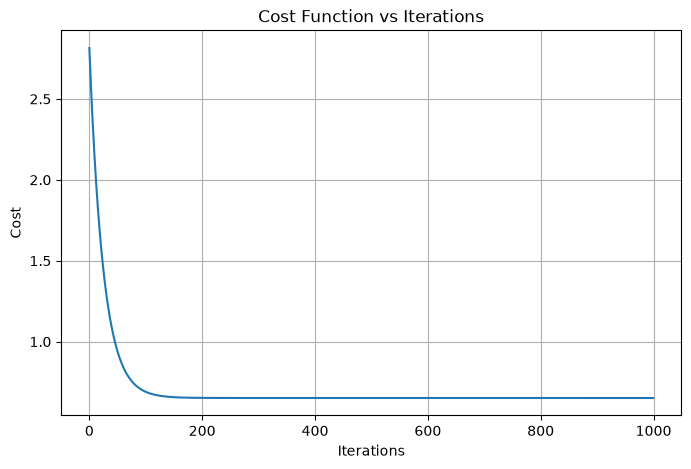

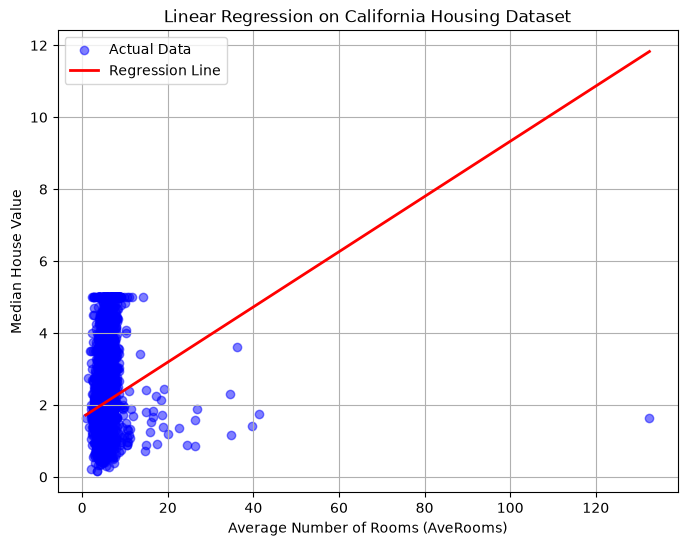

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


housing = fetch_california_housing()
X = housing.data[:, housing.feature_names.index('AveRooms')]
y = housing.target
X = X.reshape(-1, 1)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


mean = X_train.mean()
std = X_train.std()
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std


m = len(X_train)
X_b = np.c_[np.ones((m, 1)), X_train_scaled]
theta = np.zeros((2, 1))
y_train_gd = y_train.reshape(-1, 1)

learning_rate = 0.01
iterations = 1000
cost_history = []

for i in range(iterations):
    predictions = X_b.dot(theta)
    gradients = (2 / m) * X_b.T.dot(predictions - y_train_gd)
    theta = theta - learning_rate * gradients
    cost = (1 / (2 * m)) * np.sum((predictions - y_train_gd) ** 2)
    cost_history.append(cost)

print("Theta using Gradient Descent:")
print(theta)

X_test_b = np.c_[np.ones((len(X_test_scaled), 1)), X_test_scaled]
y_pred_gd = X_test_b.dot(theta)


X_train_ne = np.c_[np.ones((len(X_train), 1)), X_train]
theta_ne = np.linalg.inv(X_train_ne.T.dot(X_train_ne)).dot(X_train_ne.T).dot(y_train)

print("\nTheta using Normal Equation:")
print(theta_ne)

X_test_ne = np.c_[np.ones((len(X_test), 1)), X_test]
y_pred_ne = X_test_ne.dot(theta_ne)


print("\nGradient Descent Results")
print("------------------------")
print("MSE:", mean_squared_error(y_test, y_pred_gd))
print("R2 :", r2_score(y_test, y_pred_gd))

print("\nNormal Equation Results")
print("-----------------------")
print("MSE:", mean_squared_error(y_test, y_pred_ne))
print("R2 :", r2_score(y_test, y_pred_ne))


plt.figure(figsize=(8, 5))
plt.plot(cost_history)
plt.title("Cost Function vs Iterations")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color='blue', alpha=0.5, label='Actual Data')
sorted_index = np.argsort(X_test[:, 0])
plt.plot(
    X_test[sorted_index],
    y_pred_ne[sorted_index],
    color='red',
    linewidth=2,
    label='Regression Line'
)
plt.xlabel("Average Number of Rooms (AveRooms)")
plt.ylabel("Median House Value")
plt.title("Linear Regression on California Housing Dataset")
plt.legend()
plt.grid(True)
plt.show()